# 01 · Preprocessing — Jansky 2021 Neuroblastoma (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative
gap**, integrate patients (Harmony), embed, and annotate the malignant
transcriptional states. Jansky et al. profile childhood **neuroblastoma** — a
neural-crest–derived tumour of the developing sympathoadrenal lineage. The
malignant compartment is uniformly **noradrenergic** (PHOX2B/HAND2/DBH/TH/GATA3):
there is no adrenergic↔mesenchymal split here (mesenchymal states are essentially
absent outside cell lines), so the compartment is organised by a **continuous
noradrenergic differentiation axis** (cycling/progenitor-like → differentiating
neuronal), not by discrete subtypes (Puram 2017, four HNSCC subtypes around a
*Mixed* hub) or a cycling-vs-embryonic split (Kürten 2021). There is therefore
**no lobe to remove**; the whole malignant manifold carries the trajectory
analysed in 02–04.

Every tunable choice is *re-derived from this dataset*, not inherited — in
particular Harmony `theta` and the number of PCs. Deliverable: `processed.h5ad`,
`samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import NearestNeighbors
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Jansky2021_Neuroendocrine | category: Neuroendocrine


### Load malignant compartment
Jansky et al. annotate cell type directly; we take their `Malignant` calls (the
loader normalises UMI counts to median library size and log1p-transforms).

In [3]:
from scripts.load import load_CCCA_adata
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())

Loading ../../../../../../data/unzip/CCCA/Data_Jansky2021_Neuroendocrine
Done.
full atlas: (64769, 26344)
malignant: (28116, 26344) | samples: 14


### Sample thresholding — derived by multiplicative gap-finding
Malignant calls in the CD45⁺/normal-adjacent fractions are spillover specks.
Rather than a round-number cut, find the largest **multiplicative** cliff in the
sorted per-sample counts and cut at its geometric mean — the natural separatrix
between tumour-bearing samples and spillover. Here the dominant cliff is at the
**tail** (a single 129-cell sample falls off a 4.4× cliff), so only that speck is
dropped; the counts otherwise decline smoothly with no head cliff.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
dominance = ratios[gap] / np.sort(ratios)[-2]
print('sorted per-sample counts:', n.values.tolist())
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}, {dominance:.2f}x next-largest)')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [5907, 3809, 3243, 2689, 2209, 1953, 1751, 1732, 1435, 1217, 895, 586, 561, 129]
largest gap: 561 -> 129 (ratio 4.35, 2.80x next-largest)
derived threshold (geometric mean across the gap) = 269
kept 13/14 samples -> 27987 cells


### Overdispersion, PCA, Harmony integration, embedding — parameters derived here
Two constants are re-derived from Jansky:

- **`n_pcs = 20`** — malignant neuroblastoma variance is spread broadly (PC1 ≈ 8.5%,
  a shallow scree with no sharp elbow; ~32% cumulative by PC20). Twenty PCs capture
  the differentiation structure while staying above the noise floor; fewer discards
  real gradient, more trails into patient/CNV noise.
- **`theta = 5`** — chosen by a same-sample-neighbour-fraction sweep (θ 0/1/2/3/5/8)
  read in the downstream 20-PC space. Mixing rises and **plateaus at θ=5** (θ=8 adds
  nothing), which collapses patient structure toward the mixing floor while preserving
  the differentiation biology. A single θ does not transfer across datasets.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print(f'PC1={vr[0]*100:.1f}%  PC2={vr[1]*100:.1f}%  cumulative@20PC={np.cumsum(vr)[19]:.2f}')
sce.pp.harmony_integrate(adata, 'sample', theta=5, max_iter_harmony=20, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=15, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 941 over-dispersed features (0:00:04) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 941
PC1=8.5%  PC2=3.3%  cumulative@20PC=0.32
2026-07-30 16:57:10,551 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-07-30 16:57:16,248 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-07-30 16:57:16,524 - harmonypy - INFO - Iteration 1 of 20
2026-07-30 16:57:27,827 - harmonypy - INFO - Iteration 2 of 20
2026-07-30 16:57:39,981 - harmonypy - INFO - Iteration 3 of 20
2026-07-30 16:57:51,469 - harmonypy - INFO - Iteration 4 of 20
2026-07-30 16:58:03,487 - harmonypy - INFO - Iteration 5 of 20
2026-07-30 16:58:10,787 - harmonypy - INFO - Iteration 6 of 20
2026-07-30 16:58:16,3

### Manifold continuity — kNN connectivity (no island removal)
Continuity is certified on the kNN graph the trajectory actually traverses: a
single connected component means one continuous manifold. Neuroblastoma has no
detached specks to strip here, so **all cells are retained** (no radius-graph
island removal, which would discard real malignant cells).

In [6]:
ncomp, lab = connected_components(adata.obsp['connectivities'], directed=False)
sizes = pd.Series(lab).value_counts().values
print(f'kNN graph connected components: {ncomp} | component sizes: {sizes.tolist()}')
assert ncomp == 1, 'manifold is not a single kNN component'
print('single connected kNN component -> continuous manifold, all cells retained')

kNN graph connected components: 1 | component sizes: [27987]
single connected kNN component -> continuous manifold, all cells retained


### Malignant-state annotation (data-driven, biology-labelled)
Low-resolution Leiden recovers the coarse structure of the continuum. Every
malignant cell is **noradrenergic** (Jansky et al.'s framework — the tumour
recapitulates the sympathoadrenal noradrenergic lineage), confirmed by near-ubiquitous
detection of the core noradrenergic TFs (PHOX2B/HAND2/DBH/TH/GATA3). Clusters are
then labelled **by biology** from two data-derived programmes overlaid on that shared
noradrenergic identity: a **neuronal-differentiation** score (ELAVL4/STMN2/GAP43/NEFM/DCX/NRG1)
and a **cell-cycle** score (MKI67/TOP2A/CENPF) — dividing the continuum into a
cycling/progenitor-like pole and a differentiating-neuronal pole. `cell_cycle_phase`
comes from the loader's phase calls; neuroblastoma has **no distinct cycling lobe**
(only a scattered minority), so the trajectory is not split off a cycling compartment.

In [7]:
sc.tl.leiden(adata, resolution=0.3, key_added='state_raw', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
noradr = ['PHOX2B','HAND2','DBH','TH','GATA3','PHOX2A','ISL1']
neuron = ['ELAVL4','STMN2','GAP43','NEFM','DCX','NRG1','CNTNAP2']
cycle  = ['MKI67','TOP2A','CENPF','UBE2C','BIRC5']
for nm, gs in [('Noradrenergic', noradr), ('Neuronal', neuron), ('Cycle', cycle)]:
    sc.tl.score_genes(adata, [g for g in gs if g in adata.var_names], score_name=nm, random_state=SEED)
# confirm universal noradrenergic identity (raw detection of core TFs)
core = [g for g in ['PHOX2B','HAND2','GATA3'] if g in adata.var_names]
Xc = adata[:, core].X; Xc = Xc.toarray() if hasattr(Xc,'toarray') else np.asarray(Xc)
print('core noradrenergic TF detection fraction:', {core[i]: round((Xc[:,i]>0).mean(),2) for i in range(len(core))})
csize = adata.obs['state_raw'].value_counts()
prof = adata.obs.groupby('state_raw', observed=True)[['Noradrenergic','Neuronal','Cycle']].mean()
prof['n'] = csize
print('per-cluster mean programme scores:'); print(prof.round(3).to_string())
# Two-state continuum. Leiden can shed tiny (<2%) specks (a small cycling progenitor
# pool); merge each into the dominant cluster nearest in neuronal-maturation score,
# then split the dominant clusters at their neuronal median (low -> progenitor pole,
# high -> differentiating pole). Robust to Leiden speckiness, no forced balance.
frac = csize / csize.sum()
dominant = frac.index[frac >= 0.02]
merged = adata.obs['state_raw'].astype(str).copy()
for c in prof.index:
    if c not in dominant:
        near = min(dominant, key=lambda d: abs(prof.loc[c,'Neuronal'] - prof.loc[d,'Neuronal']))
        merged[merged == c] = near
adata.obs['state_dom'] = merged
dprof = adata.obs.groupby('state_dom', observed=True)['Neuronal'].mean()
thr = float(np.median([prof.loc[c,'Neuronal'] for c in dominant]))
lab_map = {c: ('Differentiating noradrenergic' if dprof[c] >= thr
               else 'Noradrenergic progenitor') for c in dprof.index}
adata.obs['state'] = adata.obs['state_dom'].map(lab_map).astype('category')
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print(f'dominant clusters (>=2%): {list(dominant)} | neuronal median split @ {thr:.3f}')
print('cluster -> state:', lab_map)
print('state sizes:', adata.obs['state'].value_counts().to_dict())
# state-resolved cycling/neuronal (confirms progenitor pole is more cycling, less neuronal)
sp_prof = adata.obs.groupby('state', observed=True)[['Neuronal','Cycle']].mean()
print('state programme means:'); print(sp_prof.round(3).to_string())
print(f'cycling fraction (whole manifold): {adata.obs["cycling"].mean():.3f}')

core noradrenergic TF detection fraction: {'PHOX2B': np.float64(0.18), 'HAND2': np.float64(0.37), 'GATA3': np.float64(0.41)}
per-cluster mean programme scores:
           Noradrenergic  Neuronal  Cycle      n
state_raw                                       
0                  0.017     0.344 -0.005  17222
1                 -0.003     0.427 -0.004  10654
2                  0.230     0.143  0.053     87
3                 -0.009     0.076  0.060     24
dominant clusters (>=2%): ['0', '1'] | neuronal median split @ 0.386
cluster -> state: {'0': 'Noradrenergic progenitor', '1': 'Differentiating noradrenergic'}
state sizes: {'Noradrenergic progenitor': 17333, 'Differentiating noradrenergic': 10654}
state programme means:
                               Neuronal  Cycle
state                                         
Differentiating noradrenergic     0.427 -0.004
Noradrenergic progenitor          0.343 -0.005
cycling fraction (whole manifold): 0.035


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The
same-sample-neighbour fraction quantifies mixing (1.0 = perfect patient islands;
the mixing null = Σpᵢ² for sample proportions pᵢ). Visual confirmation follows in
`samples.pdf`.

In [8]:
k = 15
nn = NearestNeighbors(n_neighbors=k+1).fit(adata.obsm['X_pca_harmony'][:, :20])
_, idx = nn.kneighbors(adata.obsm['X_pca_harmony'][:, :20])
s = adata.obs['sample'].values
ssf = np.mean([(s[idx[i,1:]] == s[i]).mean() for i in range(len(s))])
p = adata.obs['sample'].value_counts(normalize=True).values
null = float((p**2).sum())
print(f'{adata.obs["sample"].nunique()} samples on one continuous kNN manifold')
print(f'same-sample-neighbour fraction (integrated) = {ssf:.3f}  (perfect islands 1.0, mixing null {null:.3f})')
print('Gate 1: samples intermixed on one continuous manifold -> GO')

13 samples on one continuous kNN manifold
same-sample-neighbour fraction (integrated) = 0.233  (perfect islands 1.0, mixing null 0.111)
Gate 1: samples intermixed on one continuous manifold -> GO


### Save processed data

In [9]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (27987, 25323)


### Sample-integration figure (deliverable)
House style: `figsize=(3.5,1.5)`, `size=30`, colour = sample. Intermixing across
the manifold is the Gate-1 batch-integration evidence (orientation is immaterial
for this categorical panel; the pseudotime orientation is fixed in 02).

saved samples.pdf | cells: 27987


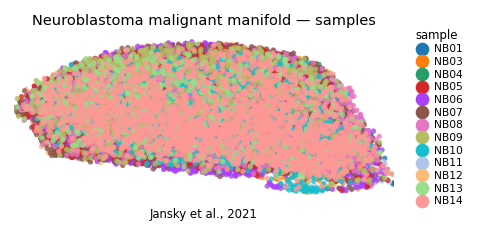

In [10]:
xy = adata.obsm['X_umap'].astype(float)
xlo,xhi = np.percentile(xy[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xy[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Neuroblastoma malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Jansky et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', adata.shape[0])